<a href="https://colab.research.google.com/github/ShivanshMishra659/mlprojects/blob/main/Toy_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('/content/placement.csv')

# df is data frame

In [3]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [4]:
df = df.iloc[:,1:]

In [5]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


#### Steps

###### 0. Preprocessing + EDA + Feature Selection
###### 1. Extract input and output cols
###### 2. Scale the values
###### 3. Train test split
###### 4. Train the model
###### 5. Evaluate the model/model selection
###### 6. Deploy the model

In [6]:
df.shape

(100, 3)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [8]:
import matplotlib.pyplot as plt

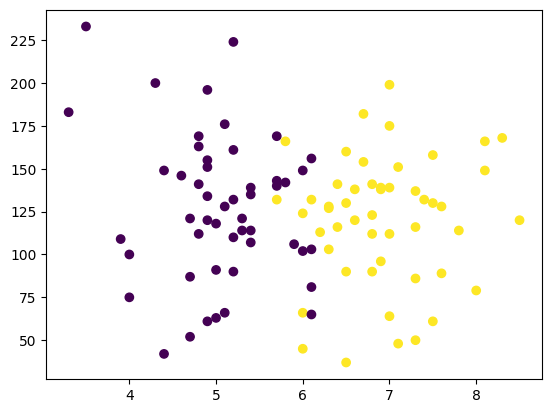

In [9]:
plt.scatter(df['cgpa'],df['iq'], c=df['placement'])

##### yellow - placement done
##### blue   - placement not done

In [10]:
x = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [14]:
 x

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [15]:
y.shape

(100,)

In [18]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.1)
# x - independent variable
# y - dependent variable

In [25]:
from sklearn.preprocessing import StandardScaler

In [26]:
scaler = StandardScaler()

In [30]:
x_train = scaler.fit_transform(x_train)

In [31]:
x_train

array([[-0.91458249,  0.8261933 ],
       [ 0.31658625,  0.12233694],
       [ 1.19599248, -1.81326804],
       [-0.56281999, -0.20445351],
       [ 0.140705  , -0.48096851],
       [ 0.84422999,  0.42398966],
       [-0.47487937,  0.32343875],
       [-0.2110575 ,  1.17812147],
       [ 0.49246749,  0.95188193],
       [ 1.81157685, -1.08427396],
       [-0.65076062, -0.80775896],
       [-1.17840436,  0.59995375],
       [ 1.37187373,  0.19775012],
       [ 0.05276437, -0.50610624],
       [ 0.66834874,  1.50491193],
       [ 1.28393311,  0.24802557],
       [ 0.05276437, -1.41106441],
       [-1.7060481 , -1.18482487],
       [-0.65076062,  2.56069646],
       [-0.91458249, -0.05362715],
       [ 0.49246749, -0.80775896],
       [ 1.19599248, -0.15417806],
       [-0.65076062,  0.97701966],
       [-1.09046373, -0.02848942],
       [-0.12311687,  0.49940284],
       [-0.73870124,  0.14747467],
       [ 0.31658625, -0.48096851],
       [ 1.89951747,  0.67536693],
       [ 1.19599248,

In [33]:
x_test = scaler.transform(x_test)

In [34]:
x_test

array([[-0.65076062, -0.30500442],
       [ 0.05276437,  0.04692376],
       [ 1.37187373,  0.90160648],
       [ 1.02011124,  0.72564239],
       [-0.91458249,  1.8568401 ],
       [ 0.93217061,  1.93225329],
       [ 1.45981435,  0.14747467],
       [-0.82664186, -0.78262124],
       [ 0.58040812, -0.05362715],
       [ 1.45981435, -0.83289669]])

In [36]:
from sklearn.linear_model import LogisticRegression

In [37]:
clf = LogisticRegression()

In [40]:
# model training
clf.fit(x_train, y_train)

LogisticRegression()

In [44]:
y_pred = clf.predict(x_test)

In [45]:
y_test

,placement
92,0
27,1
91,1
21,1
80,0
26,1
30,1
25,0
20,1
42,1


In [46]:
from sklearn.metrics import accuracy_score

In [47]:
accuracy_score(y_test, y_pred)

0.9

In [48]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

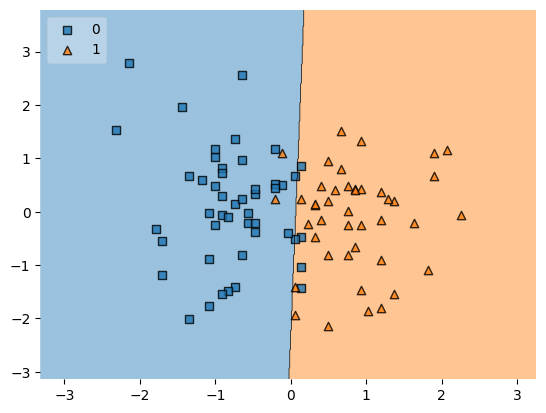

In [51]:
plot_decision_regions(x_train, y_train.values, clf=clf, legend=2)

In [52]:
import pickle

In [53]:
pickle.dump(clf,open('model.pkl','wb'))